# Temas por año: ¿de qué habla la Universidad de Sonora y cómo ha cambiado? (2015–2026)

En el notebook `01_exploracion`, TF-IDF por año sugirió que las noticias pasan por **tres etapas**:
la universidad de antes (2015–2019), la pandemia (2020–2022) y la universidad de ahora (2023–2026).
En este notebook profundizamos en esa idea para construir una historia:

1. **Preparar el texto:** limpieza y normalización (lematización con spaCy).
2. **¿De verdad hay etapas?** Comparamos el vocabulario de cada año con el de los demás.
3. **¿Qué distingue a cada etapa?** Los temas y nombres característicos de cada una.
4. **¿Qué sube y qué baja?** Lo que gana y pierde espacio entre la primera y la última etapa.
5. **Cuatro historias de cambio:** la estructura, las personas, la forma de escribir y los temas nuevos, año por año.

## 1. Librerías

In [1]:
import json
import os
import re
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from wordcloud import WordCloud
import nltk
from nltk.corpus import stopwords
from nltk.stem import SnowballStemmer
import spacy

## 2. Carga de datos

Igual que en el notebook 01: leemos el JSONL, nos quedamos con las noticias válidas y quitamos las casi vacías.

In [2]:
registros = []
with open("data/raw/noticias_unison.jsonl", encoding="utf-8") as archivo:
    for linea in archivo:
        try:
            registros.append(json.loads(linea))
        except json.JSONDecodeError:
            pass  # línea incompleta mientras el scraper escribe

noticias = pd.DataFrame(registros)
noticias = noticias[noticias["estado"] == "ok"].drop_duplicates(subset="id", keep="last")
noticias = noticias.sort_values("id").reset_index(drop=True)

noticias["fecha"] = pd.to_datetime(noticias["fecha"])
noticias["anio"] = noticias["fecha"].dt.year
noticias["n_palabras"] = noticias["n_palabras"].astype(int)
noticias = noticias[noticias["n_palabras"] >= 30].reset_index(drop=True)

noticias = noticias[["id", "fecha", "anio", "titulo", "texto"]]
noticias_por_anio = noticias["anio"].value_counts().sort_index()

print("Noticias:", len(noticias))
noticias_por_anio

Noticias: 19813


anio
2015    2377
2016    2337
2017    2052
2018    2058
2019    1705
2020     946
2021    1356
2022    1613
2023    1650
2024    1457
2025    1313
2026     949
Name: count, dtype: int64

## 3. Limpieza

En el notebook 01 encontramos texto que no es parte de la noticia y que ensucia el análisis de palabras:

- **Firmas al final:** iniciales o nombres entre paréntesis, como *(JAR)*, *(BE)* o *(Cruz Teros-AZ)*.
- **Firmas al inicio** que el scraper no reconoció: *Redacción*, *Paula Trespalacios Argain.* Son primeras líneas de 4 palabras o menos.
- **Enlaces y correos:** por ejemplo los de WeTransfer con el audio y las fotos de la nota.

In [3]:
def limpiar(texto):
    """Quita firmas, enlaces y correos del texto de una noticia."""
    texto = texto.strip()
    texto = re.sub(r"\([^()]{1,40}\)\.?$", "", texto)       # firma al final: "(JAR)", "(Cruz Teros-AZ)."

    lineas = texto.split("\n")
    if len(lineas[0].split()) <= 4:                            # firma al inicio: "Redacción"
        lineas = lineas[1:]
    texto = "\n".join(lineas)

    texto = re.sub(r"https?://\S+|www\.\S+", " ", texto)    # enlaces
    texto = re.sub(r"\S+@\S+", " ", texto)                   # correos
    return texto


noticias["texto_limpio"] = noticias["texto"].apply(limpiar)

cambiaron = noticias["texto"].str.strip() != noticias["texto_limpio"].str.strip()
print("Noticias que cambiaron con la limpieza:", cambiaron.sum())

Noticias que cambiaron con la limpieza: 9152


Un ejemplo con firma al final y un enlace:

In [4]:
con_enlace_y_firma = noticias["texto"].str.contains("http") & noticias["texto"].str.strip().str.endswith(")")
ejemplo = noticias[con_enlace_y_firma].iloc[0]

print("ANTES:   ...", ejemplo["texto"].strip()[-160:])
print()
print("DESPUÉS: ...", ejemplo["texto_limpio"].strip()[-160:])

ANTES:   ... s días 27 de diciembre y el 3 de enero de 2015, a las 12:00 horas, o por internet, en la página http://www.uson.mx/medios_informativos/desdelauniversidad/. (EQ)

DESPUÉS: ... ás información sobresaliente de 2014 se podrá ver por Canal 8, los días 27 de diciembre y el 3 de enero de 2015, a las 12:00 horas, o por internet, en la página


## 4. Normalización

Para contar temas queremos que las distintas formas de una palabra cuenten como una sola:
*sismo* y *sismos*, *navideña* y *navideños*, *dijo* y *dijeron*. Hay dos formas clásicas de hacerlo:

- **Stemming** (raíz): corta la terminación con reglas. Es rápido, pero no sabe español: a veces corta de más.
- **Lematización** (lema): usa un modelo del idioma para llevar cada palabra a su forma de diccionario.

### 4.1 Stemming vs. lematización

Comparamos las dos con una frase de prueba. Para lematizar usamos **spaCy** con su modelo pequeño de español;
desactivamos las partes del modelo que no necesitamos (análisis sintáctico y entidades) para que sea más rápido.

In [5]:
nltk.download("stopwords", quiet=True)
stopwords_es = set(stopwords.words("spanish"))

nlp = spacy.load("es_core_news_sm", disable=["parser", "ner"])
stemmer = SnowballStemmer("spanish")

frase = ("La rectora y el rector inauguraron las posadas navideñas. Las mujeres hablaron de los sismos "
         "y de la inteligencia artificial; los estudiantes dijeron que estudian ciencias.")

comparacion = pd.DataFrame(
    [(token.text, stemmer.stem(token.text.lower()), token.lemma_.lower(), token.pos_)
     for token in nlp(frase) if token.is_alpha],
    columns=["palabra", "stemming", "lema", "categoría"],
)
comparacion[~comparacion["palabra"].str.lower().isin(stopwords_es)]

,palabra,stemming,lema,categoría
1,rectora,rector,rectora,NOUN
4,rector,rector,rector,NOUN
5,inauguraron,inaugur,inaugurar,VERB
7,posadas,pos,posada,ADJ
8,navideñas,navideñ,navideño,ADJ
10,mujeres,mujer,mujer,NOUN
11,hablaron,habl,hablar,VERB
14,sismos,sism,sismo,NOUN
18,inteligencia,inteligent,inteligencia,NOUN
19,artificial,artificial,artificial,ADJ


El stemming junta *rectora* con *rector* (justo un cambio que queremos poder ver), separa *mujer* (*muj*) de *mujeres* (*mujer*)
y deja raíces difíciles de leer (*inteligent*, *estudi*). La lematización junta las formas de cada palabra y deja
palabras reales. **Usamos lemas.**

### 4.2 ¿Qué palabras conservamos?

spaCy también nos dice la **categoría** de cada palabra (la columna de la tabla anterior). La usamos para separar
el vocabulario en dos grupos:

- **Temas:** sustantivos y adjetivos (*pandemia, virtual, semiconductor*). Dicen **de qué** se habla.
- **Nombres:** nombres propios (*Conahcyt, Zoom, Hermosillo, María Rita Plancarte*). Dicen **quién** y **dónde**:
  personas, lugares e instituciones.

Los verbos (*dijo, señaló*) quedan fuera; eran los que llenaban las nubes del notebook 01.

Además guardamos **bigramas**: dos palabras del mismo grupo seguidas, permitiendo en medio solo artículos y preposiciones.
Así *inteligencia artificial*, *cáncer de mama* (→ *cáncer mama*) o *Unidad Regional* cuentan como un término propio.
En los bigramas usamos las palabras tal como aparecen (en minúsculas) y no el lema, porque spaCy pasa los adjetivos
a masculino: *contingencia sanitaria* quedaría como *contingencia sanitario*.

*Nota:* intentamos usar el reconocimiento de entidades de spaCy para separar personas de instituciones,
pero el modelo pequeño confunde mucho (marca *Zoom* y *Conacyt* como personas), así que nos quedamos con la categoría gramatical.

In [6]:
TIPO = {"NOUN": "temas", "ADJ": "temas", "PROPN": "nombres"}   # sustantivos y adjetivos / nombres propios
UNEN = {"ADP", "DET"}                                           # preposiciones y artículos no cortan un bigrama


def lematizar(doc):
    """Lemas de un texto separados en temas (sustantivos y adjetivos) y nombres propios, con sus bigramas."""
    terminos = {"temas": [], "nombres": []}
    anterior = None          # (tipo, palabra) de la palabra de contenido anterior
    for token in doc:
        lema = token.lemma_.lower()
        tipo = TIPO.get(token.pos_)
        if tipo is not None and token.is_alpha and lema not in stopwords_es:
            terminos[tipo].append(lema)
            if anterior is not None and anterior[0] == tipo:      # dos palabras del mismo tipo seguidas
                terminos[tipo].append(anterior[1] + " " + token.lower_)
            anterior = (tipo, token.lower_)
        elif token.pos_ not in UNEN:
            anterior = None  # un verbo, un signo de puntuación, etc. corta el bigrama
    return terminos["temas"], terminos["nombres"]


otra_frase = ("La contingencia sanitaria obligó a dar clases virtuales por Microsoft Teams; la rectora María Rita Plancarte "
              "habló del cáncer de mama en la Unidad Regional Norte.")

temas, nombres = lematizar(nlp(otra_frase))
print("Temas:  ", temas)
print("Nombres:", nombres)

Temas:   ['contingencia', 'sanitario', 'contingencia sanitaria', 'clase', 'virtual', 'clases virtuales', 'rectora', 'cáncer', 'mama', 'cáncer mama']
Nombres: ['microsoft', 'teams', 'microsoft teams', 'maría', 'rita', 'maría rita', 'plancarte', 'rita plancarte', 'unidad', 'regional', 'unidad regional', 'norte', 'regional norte']


### 4.3 Lematizar todas las noticias

spaCy tarda **unos 10 minutos** en procesar las ~19,800 noticias, así que guardamos el resultado en
`data/processed/noticias_lemas.jsonl` y las siguientes veces solo lo leemos.
*Si se vuelve a correr el scraper, hay que borrar ese archivo para que se recalcule.*

In [7]:
RUTA_LEMAS = "data/processed/noticias_lemas.jsonl"

if os.path.exists(RUTA_LEMAS):
    lemas = pd.read_json(RUTA_LEMAS, lines=True)
else:
    filas = []
    for id_noticia, doc in zip(noticias["id"], nlp.pipe(noticias["texto_limpio"], batch_size=50)):
        temas, nombres = lematizar(doc)
        filas.append({"id": id_noticia, "temas": temas, "nombres": nombres})
    lemas = pd.DataFrame(filas)
    os.makedirs("data/processed", exist_ok=True)
    lemas.to_json(RUTA_LEMAS, orient="records", lines=True, force_ascii=False)

noticias = noticias.merge(lemas, on="id")
noticias["terminos"] = noticias["temas"] + noticias["nombres"]   # los dos grupos juntos

print("Noticias con lemas:", len(noticias))
noticias[["titulo", "temas", "nombres"]].head()

Noticias con lemas: 19813


,titulo,temas,nombres
0,Presenta DSD la Universidad resumen especial d...,"[comunidad, estudiantil, comunidad estudiantil...","[universidad, sonora, universidad sonora, univ..."
1,Impulsar geoturismo como potencial de desarrol...,"[geoturismo, gran, potencial, gran potencial, ...","[sonora, rafael, pacheco, rafael pacheco, rodr..."
2,Tarde de buen cine mexicano este 4 de enero de...,"[domingo, entretenimiento, domingos entretenim...","[televisión, universitaria, televisión univers..."
3,Se espera mayor movilidad del dólar y crecimie...,"[favorable, expectativa, economía, expectativa...","[unidos, germán, palafox, germán palafox, moye..."
4,Será en línea registro para examen de colocaci...,"[inglés, idioma, semestre, idioma semestre, re...","[departamento, lenguas, departamento lenguas, ..."


## 5. ¿De verdad hay etapas?

Si las noticias cambian por etapas, los años de una misma etapa deberían **parecerse entre sí** más que a los de otras.
Para medirlo describimos cada año con el **porcentaje de sus noticias que usa cada término** y comparamos esos perfiles.

### 5.1 ¿En cuántas noticias aparece cada término?

Una función que cuenta, para cada grupo de noticias (un año, o más adelante una etapa), en cuántas aparece cada término.

In [8]:
def contar_noticias(columna, por):
    """Tabla de términos x grupos: en cuántas noticias de cada grupo aparece cada término de `columna`."""
    conteos = {}
    for grupo, noticias_del_grupo in noticias.groupby(por):
        conteo = Counter()
        for terminos in noticias_del_grupo[columna]:
            conteo.update(set(terminos))      # set: cada término cuenta una vez por noticia
        conteos[grupo] = conteo
    return pd.DataFrame(conteos).fillna(0)   # filas: términos, columnas: grupos


conteo_anio = contar_noticias("terminos", "anio")
porcentaje_anio = conteo_anio / noticias_por_anio * 100   # % de las noticias de cada año

print("Términos distintos:", len(conteo_anio))
porcentaje_anio.loc[["pandemia", "campus", "rectora", "inteligencia artificial"]].round(1)

Términos distintos: 627249


,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
pandemia,0.2,0.0,0.1,0.0,0.1,22.0,30.2,19.3,7.8,3.6,3.4,1.4
campus,26.8,27.4,23.8,25.8,27.1,29.4,25.1,27.8,37.2,40.4,45.6,47.3
rectora,0.5,0.1,0.3,0.0,0.1,0.3,8.3,9.8,12.4,12.8,15.2,15.9
inteligencia artificial,0.3,0.1,0.2,0.3,2.1,2.1,3.1,1.0,2.7,3.6,5.9,6.4


### 5.2 Similitud entre años

Usamos la **similitud coseno**, la medida más común para comparar textos: vale **1** si dos años usan los mismos términos
en las mismas proporciones y baja conforme su vocabulario se separa.

Antes de comparar quitamos dos tipos de términos:
- Los **raros** (menos de 50 noticias en total): son demasiado ruidosos.
- Los **demasiado comunes** (más del 20% de todas las noticias, como *universidad, sonora, estudiante*): están en todos
  los años y harían que todos se parezcan.

In [9]:
total_noticias = len(noticias)
en_cuantas = conteo_anio.sum(axis=1)                      # en cuántas noticias aparece cada término (todos los años)
usados = (en_cuantas >= 50) & (en_cuantas / total_noticias <= 0.20)
perfiles = porcentaje_anio[usados]

# Similitud coseno: dividimos cada perfil (columna) entre su largo y multiplicamos todos contra todos
largo = np.sqrt((perfiles ** 2).sum())
similitud = (perfiles / largo).T @ (perfiles / largo)

print("Términos usados para comparar:", usados.sum())
similitud.round(2)

Términos usados para comparar: 7817


,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
2015,1.00,0.98,0.98,0.96,0.95,0.91,0.90,0.92,0.92,0.90,0.89,0.85
2016,0.98,1.00,0.98,0.96,0.95,0.91,0.90,0.93,0.93,0.91,0.90,0.86
2017,0.98,0.98,1.00,0.98,0.97,0.93,0.92,0.94,0.94,0.91,0.90,0.86
2018,0.96,0.96,0.98,1.00,0.98,0.93,0.91,0.93,0.92,0.90,0.89,0.86
2019,0.95,0.95,0.97,0.98,1.00,0.95,0.94,0.95,0.94,0.91,0.90,0.87
2020,0.91,0.91,0.93,0.93,0.95,1.00,0.97,0.95,0.92,0.90,0.88,0.86
2021,0.90,0.90,0.92,0.91,0.94,0.97,1.00,0.97,0.94,0.91,0.89,0.86
2022,0.92,0.93,0.94,0.93,0.95,0.95,0.97,1.00,0.97,0.94,0.92,0.88
2023,0.92,0.93,0.94,0.92,0.94,0.92,0.94,0.97,1.00,0.98,0.96,0.90
2024,0.90,0.91,0.91,0.90,0.91,0.90,0.91,0.94,0.98,1.00,0.97,0.91


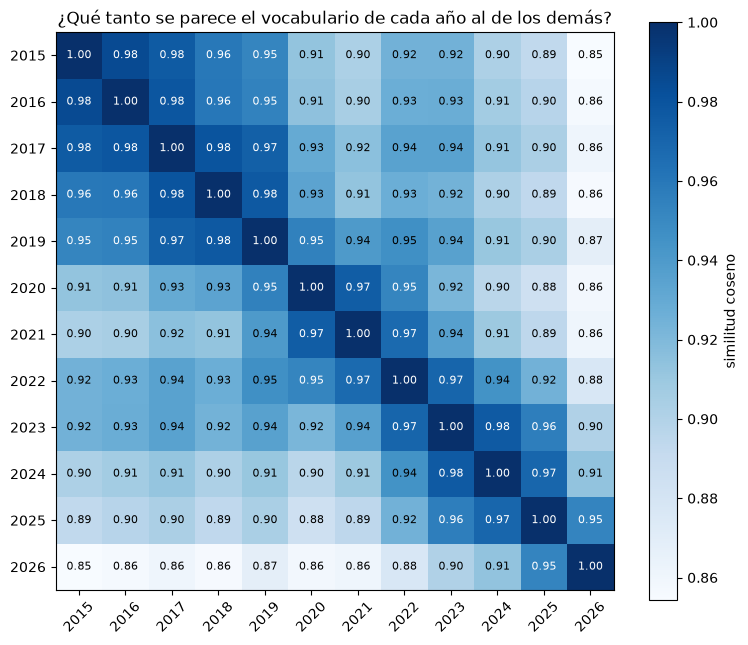

In [10]:
anios = list(similitud.columns)

plt.figure(figsize=(9, 7.5))
plt.imshow(similitud, cmap="Blues")
plt.colorbar(label="similitud coseno")
plt.xticks(range(len(anios)), anios, rotation=45)
plt.yticks(range(len(anios)), anios)

# El valor dentro de cada celda; en blanco cuando la celda es oscura
for i in range(len(anios)):
    for j in range(len(anios)):
        valor = similitud.iloc[i, j]
        color = "white" if valor > 0.95 else "black"
        plt.text(j, i, f"{valor:.2f}", ha="center", va="center", fontsize=8, color=color)

plt.title("¿Qué tanto se parece el vocabulario de cada año al de los demás?")
plt.show()

Se ven **tres bloques** de años que se parecen entre sí (cuadros oscuros sobre la diagonal):
**2015–2019**, **2020–2022** y **2023–2026**. Los datos confirman las etapas que sugería TF-IDF.
2026 se parece menos a todos porque el año va incompleto (menos noticias, perfil más ruidoso), pero su año más parecido es 2025.

## 6. ¿Qué distingue a cada etapa?

Agrupamos los años en las tres etapas y buscamos los términos que más **destacan** en cada una: cuántas veces más
se usan en la etapa que en el resto de los años (la misma idea que las nubes por mes del notebook 01).

In [11]:
def etapa(anio):
    if anio <= 2019:
        return "2015–2019"
    if anio <= 2022:
        return "2020–2022"
    return "2023–2026"


noticias["etapa"] = noticias["anio"].apply(etapa)
noticias_por_etapa = noticias["etapa"].value_counts().sort_index()
etapas = list(noticias_por_etapa.index)
noticias_por_etapa

etapa
2015–2019    10529
2020–2022     3915
2023–2026     5369
Name: count, dtype: int64

In [12]:
MINIMO_NOTICIAS_ETAPA = 30


def caracteristicos(conteo, nombre_etapa, n=12):
    """Términos que más destacan en una etapa: % de sus noticias contra % de las noticias del resto de los años."""
    en_etapa = conteo[nombre_etapa] / noticias_por_etapa[nombre_etapa] * 100
    en_resto = conteo.drop(columns=nombre_etapa).sum(axis=1) / (total_noticias - noticias_por_etapa[nombre_etapa]) * 100
    veces_mas = en_etapa / (en_resto + 0.1)              # +0.1 para no dividir entre cero con términos nuevos
    veces_mas = veces_mas[conteo[nombre_etapa] >= MINIMO_NOTICIAS_ETAPA]
    return veces_mas.sort_values(ascending=False).head(n)


conteo_temas = contar_noticias("temas", "etapa")
conteo_nombres = contar_noticias("nombres", "etapa")

print("Ejemplo: los temas que más destacan en 2020–2022")
caracteristicos(conteo_temas, "2020–2022").round(1)

Ejemplo: los temas que más destacan en 2020–2022


contingencia sanitaria    46.7
nueva normalidad          16.9
contingencia              16.3
actual pandemia           15.1
tiempos pandemia          14.6
pandemia                  14.4
través plataforma         11.9
coronavirus               11.8
sanitario                 11.5
confinamiento             11.0
forma virtual             10.5
manera virtual            10.1
dtype: float64

Los 12 temas y los 12 nombres que más destacan en cada etapa:

In [13]:
pd.DataFrame({etapa: list(caracteristicos(conteo_temas, etapa).index) for etapa in etapas})

,2015–2019,2020–2022,2023–2026
0,sistema cable,contingencia sanitaria,director administrativo
1,quiroz,nueva normalidad,administrativo campus
2,general académica,contingencia,facultades interdisciplinarias
3,dirección internet,actual pandemia,mesa presídium
4,justicia penal,tiempos pandemia,directora administrativa
5,secretario técnico,pandemia,secretario campus
6,secretarias generales,través plataforma,representación rectora
7,señal abierta,coronavirus,reciente emisión
8,secretaria general,sanitario,rectora
9,representación rector,confinamiento,administrativa campus


In [14]:
pd.DataFrame({etapa: list(caracteristicos(conteo_nombres, etapa).index) for etapa in etapas})

,2015–2019,2020–2022,2023–2026
0,cruz morales,teams,facultad interdisciplinaria
1,haydée cruz,zoom,interdisciplinaria ciencias
2,luz haydée,microsoft teams,aquí
3,león peñúñuri,covid,interdisciplinaria
4,haydée,microsoft,general facultad
5,garcía león,discriminación,interdisciplinaria ingeniería
6,guerra robles,norte urn,dirección administrativa
7,gonzález agramón,gel,maría camarena
8,magdalena gonzález,youtube,administrativo campus
9,amelia iruretagoyena,guedea,interdisciplinaria humanidades


En nubes: arriba los temas y abajo los nombres; el tamaño indica cuántas veces más se usa el término en la etapa.

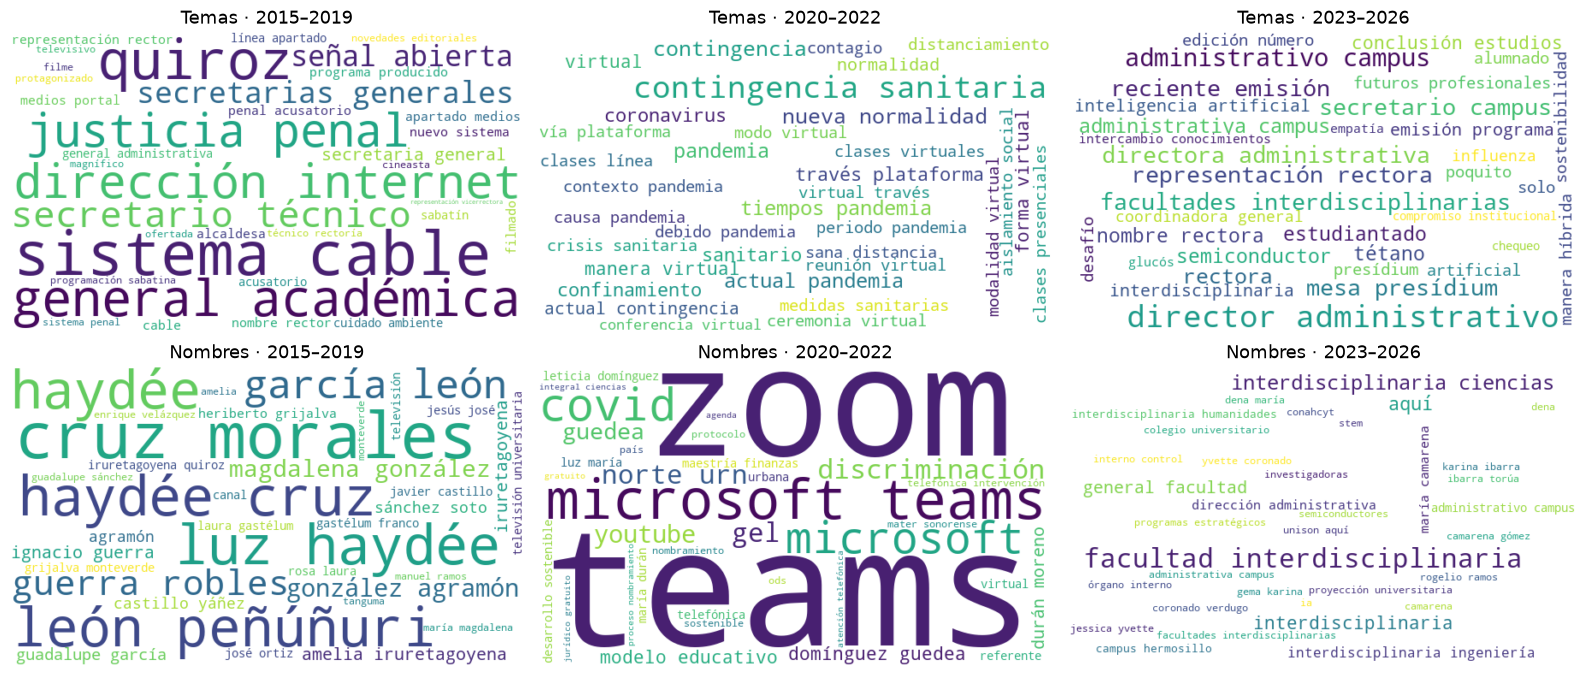

In [15]:
fig, ejes = plt.subplots(2, 3, figsize=(16, 7))

for fila, (conteo, nombre) in enumerate([(conteo_temas, "Temas"), (conteo_nombres, "Nombres")]):
    for columna, nombre_etapa in enumerate(etapas):
        eje = ejes[fila, columna]
        nube = WordCloud(width=600, height=350, background_color="white", random_state=42)
        nube.generate_from_frequencies(caracteristicos(conteo, nombre_etapa, n=35).to_dict())
        eje.imshow(nube, interpolation="bilinear")
        eje.set_title(f"{nombre} · {nombre_etapa}", fontsize=13)
        eje.axis("off")

plt.tight_layout()
plt.show()

## 7. ¿Qué sube y qué baja?

Ahora comparamos directamente la primera etapa con la última: ¿qué términos ganaron más espacio y cuáles lo perdieron?
Medimos el cambio en **puntos porcentuales** (p. ej. de 25% a 40% de las noticias = +15 puntos). A diferencia de "veces más",
esto destaca los cambios **grandes**, no los de términos raros.

In [16]:
def cambio_entre_etapas(conteo, inicio="2015–2019", final="2023–2026"):
    """Diferencia en puntos porcentuales entre dos etapas, con el % de cada una."""
    tabla = pd.DataFrame({
        inicio: conteo[inicio] / noticias_por_etapa[inicio] * 100,
        final: conteo[final] / noticias_por_etapa[final] * 100,
    })
    tabla["cambio (puntos)"] = tabla[final] - tabla[inicio]
    return tabla.sort_values("cambio (puntos)")


cambio_temas = cambio_entre_etapas(conteo_temas)
cambio_nombres = cambio_entre_etapas(conteo_nombres)

print("Temas que más bajan y más suben:")
pd.concat([cambio_temas.head(8), cambio_temas.tail(8)]).round(1)

Temas que más bajan y más suben:


,2015–2019,2023–2026,cambio (puntos)
alma,16.5,6.9,-9.6
rector,11.6,2.0,-9.6
alumno,37.3,28.2,-9.1
vicerrectora,7.9,0.4,-7.5
país,24.9,20.4,-4.5
director,20.4,16.0,-4.4
entidad,10.2,5.8,-4.4
auditorio,10.3,6.4,-4.0
oportunidad,16.3,24.7,8.4
estudiante,54.5,64.2,9.7


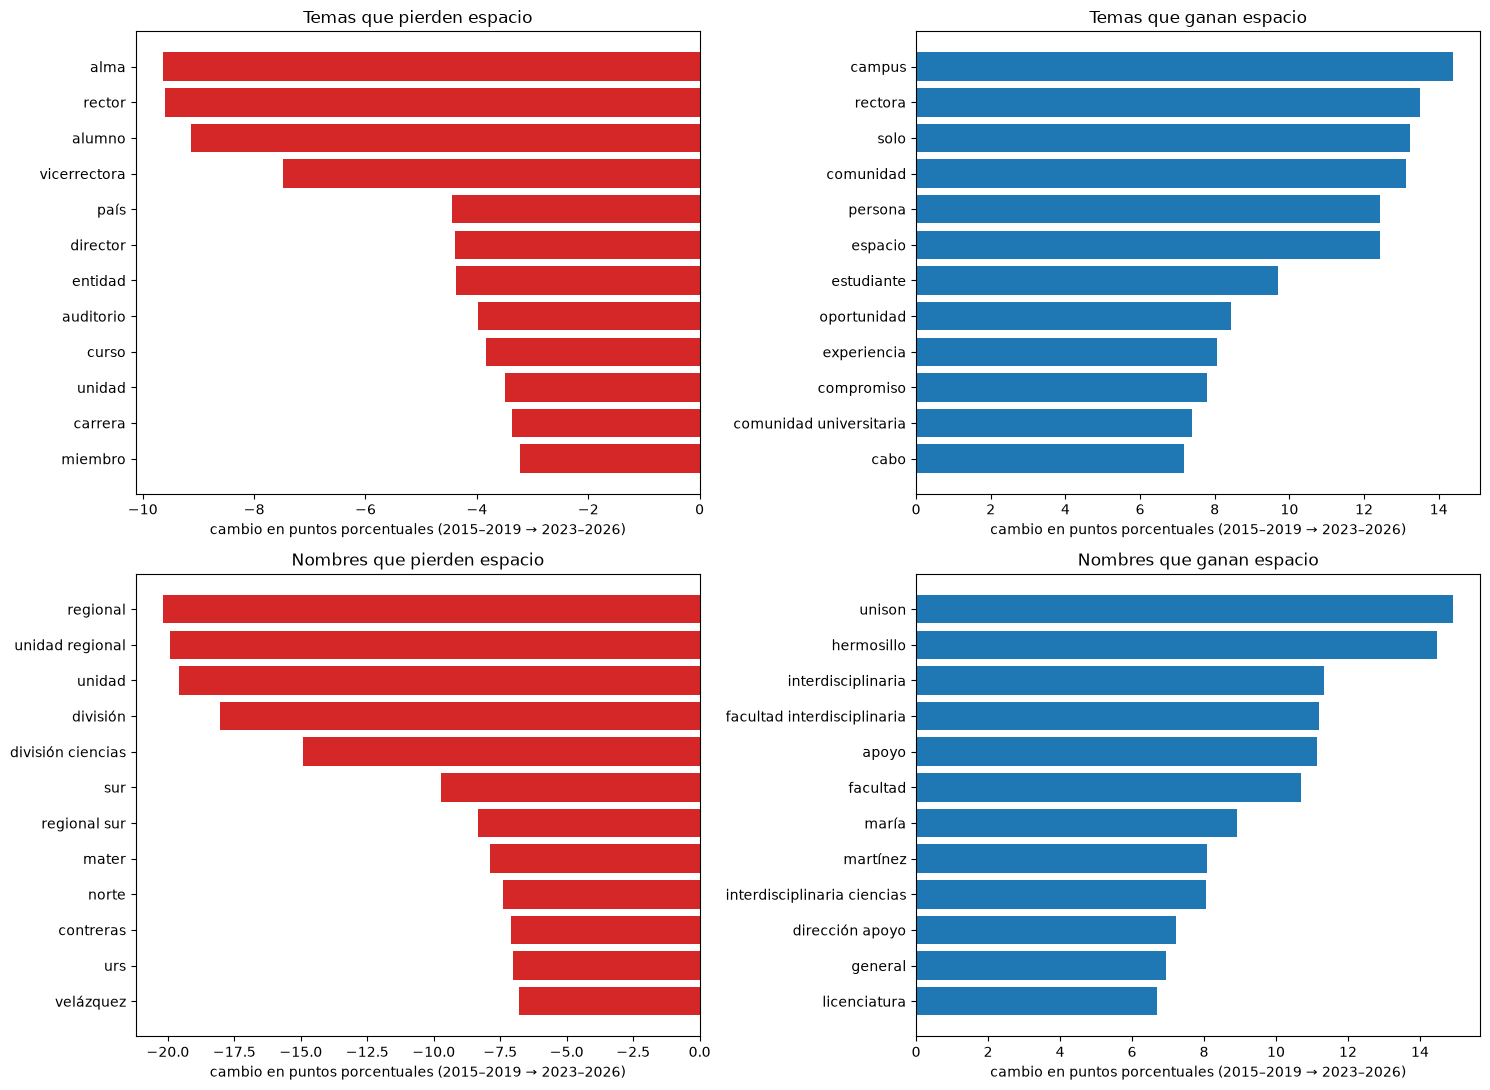

In [17]:
fig, ejes = plt.subplots(2, 2, figsize=(15, 11))

for fila, (cambio, nombre) in enumerate([(cambio_temas, "Temas"), (cambio_nombres, "Nombres")]):
    bajan = cambio["cambio (puntos)"].head(12)
    suben = cambio["cambio (puntos)"].tail(12)

    ejes[fila, 0].barh(bajan.index[::-1], bajan.values[::-1], color="tab:red")
    ejes[fila, 0].set_title(f"{nombre} que pierden espacio")
    ejes[fila, 1].barh(suben.index, suben.values, color="tab:blue")
    ejes[fila, 1].set_title(f"{nombre} que ganan espacio")
    for eje in ejes[fila]:
        eje.set_xlabel("cambio en puntos porcentuales (2015–2019 → 2023–2026)")

plt.tight_layout()
plt.show()

## 8. Cuatro historias de cambio

Las tablas de las secciones 6 y 7 mezclan cambios de naturaleza distinta. Al leerlas aparecen **cuatro historias**,
que ahora seguimos año por año buscando expresiones en el texto limpio (como en la sección 7 del notebook 01):

1. **La estructura cambia de nombre:** Unidades Regionales, Divisiones y vicerrectores dan paso a campus,
   Facultades Interdisciplinarias y directores administrativos.
2. **Cambian las personas:** cuatro rectores en doce años.
3. **Cambia la forma de escribir:** lenguaje incluyente y nuevas reglas de ortografía.
4. **Llegan temas nuevos:** la pandemia, la inteligencia artificial, los semiconductores, la salud mental.

In [18]:
def porcentaje_por_anio(patron):
    """Porcentaje de las noticias de cada año cuyo texto limpio contiene el patrón (sin distinguir mayúsculas)."""
    contiene = noticias["texto_limpio"].str.contains(patron, case=False)
    return contiene.groupby(noticias["anio"]).mean() * 100


HISTORIAS = {
    "1. La estructura cambia de nombre": {
        "Unidad Regional": "unidad regional",
        "División de ...": "división de",
        "vicerrector(a)": "vicerrector",
        "campus": r"\bcampus\b",
        "Facultad Interdisciplinaria": "facultad interdisciplinaria",
        "director(a) administrativo(a)": "director[a]? administrativ",
    },
    "2. Cuatro rectores": {
        "Heriberto Grijalva Monteverde": "heriberto grijalva",
        "Enrique F. Velázquez Contreras": "velázquez contreras",
        "María Rita Plancarte Martínez": "rita plancarte",
        "Dena María Camarena Gómez": "camarena gómez",
    },
    "3. Cambia la forma de escribir": {
        "sólo (con acento)": r"\bsólo\b",
        "solo (sin acento)": r"\bsolo\b",
        "las y los / los y las": "las y los|los y las",
        "estudiantado / alumnado / profesorado": "estudiantado|alumnado|profesorado",
        "alumno(s) / alumna(s)": r"\balumn[oa]s?\b",
    },
    "4. Temas que llegan": {
        "pandemia / covid": "pandemia|covid",
        "inteligencia artificial": "inteligencia artificial",
        "semiconductores": "semiconductor",
        "salud mental": "salud mental",
    },
}

series = {}
for historia, patrones in HISTORIAS.items():
    for etiqueta, patron in patrones.items():
        series[etiqueta] = porcentaje_por_anio(patron)

pd.DataFrame(series).T.round(1)

anio,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
Unidad Regional,20.4,18.5,20.4,27.5,24.0,25.2,21.9,20.3,6.1,0.3,0.2,0.2
División de ...,20.0,19.9,18.5,20.4,20.9,21.0,19.2,19.3,6.2,1.6,0.9,0.3
vicerrector(a),12.3,11.0,13.1,15.1,13.0,13.2,13.5,11.5,2.7,0.1,0.2,0.6
campus,26.8,27.4,23.8,25.8,27.1,29.4,25.1,27.8,37.2,40.5,45.6,47.3
Facultad Interdisciplinaria,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,6.4,13.0,13.6,14.1
director(a) administrativo(a),0.0,0.0,0.0,0.0,0.0,0.1,0.1,0.1,5.2,10.0,11.7,13.8
Heriberto Grijalva Monteverde,7.0,9.5,4.6,0.1,0.3,0.0,0.4,0.5,0.5,0.3,1.1,0.2
Enrique F. Velázquez Contreras,2.4,2.6,8.9,12.1,13.4,11.8,5.3,0.9,0.7,0.5,0.8,1.1
María Rita Plancarte Martínez,0.4,0.4,3.2,4.0,4.8,4.3,9.7,9.5,11.9,12.6,6.5,0.3
Dena María Camarena Gómez,0.1,0.0,0.1,0.3,0.7,0.5,0.4,0.9,0.7,1.4,9.6,15.4


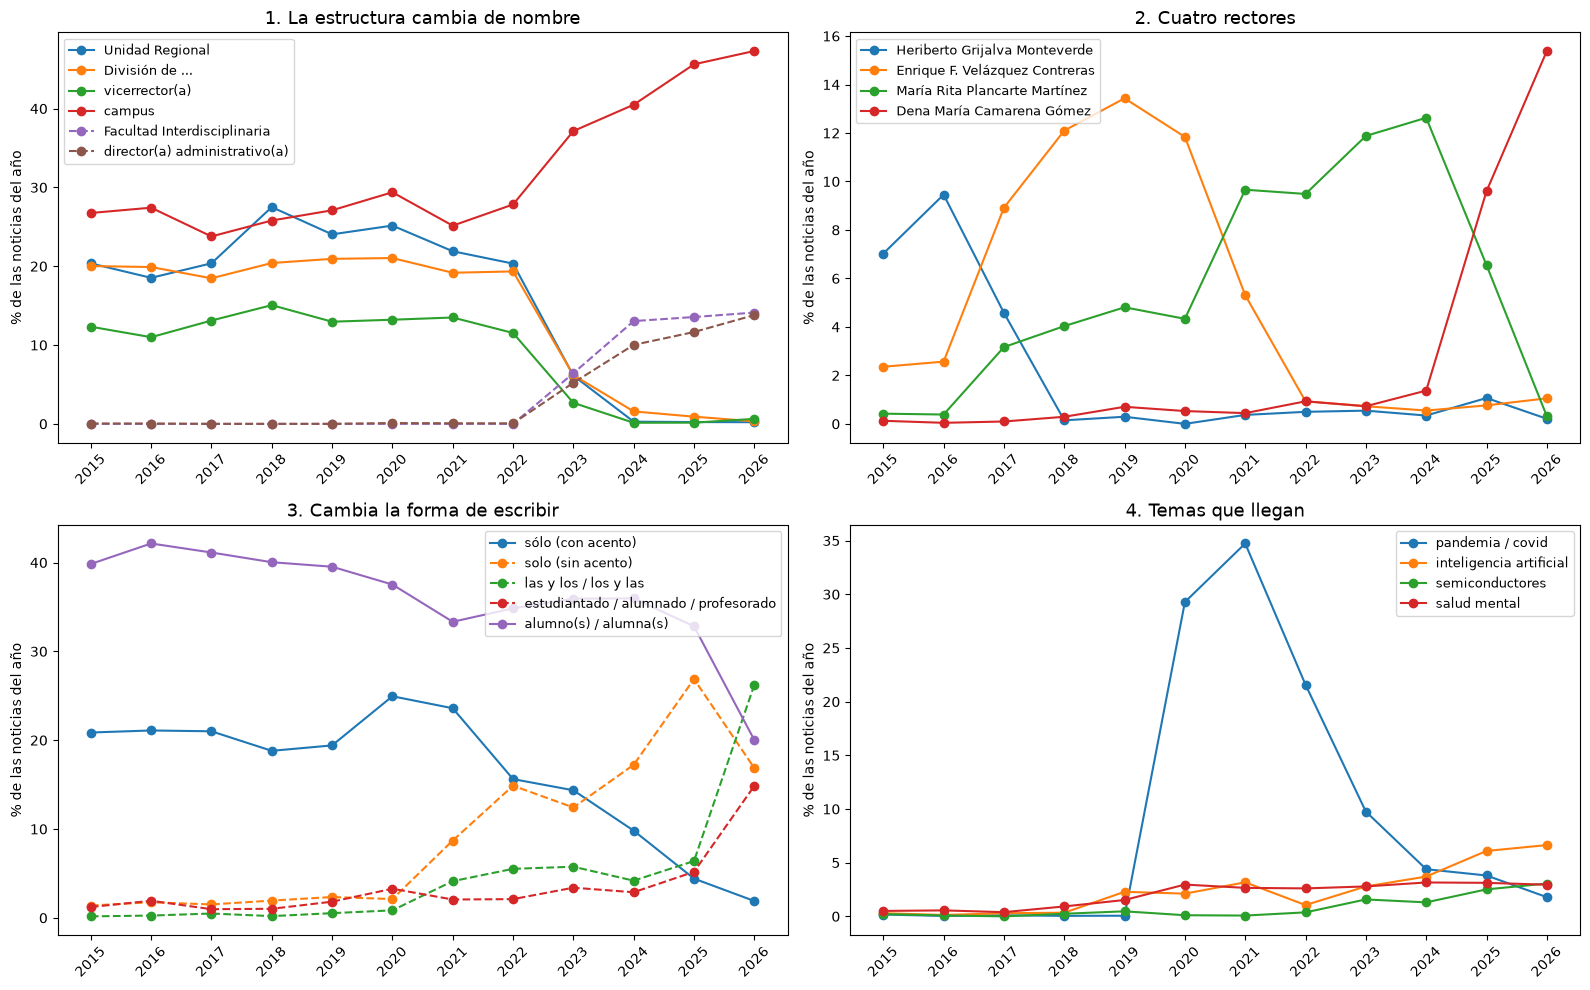

In [19]:
# Líneas punteadas para lo que llega después; continuas para lo que ya existía
LLEGAN = {"Facultad Interdisciplinaria", "director(a) administrativo(a)",
          "solo (sin acento)", "las y los / los y las", "estudiantado / alumnado / profesorado"}

fig, ejes = plt.subplots(2, 2, figsize=(16, 10))

for (historia, patrones), eje in zip(HISTORIAS.items(), ejes.flatten()):
    for etiqueta in patrones:
        estilo = "--" if etiqueta in LLEGAN else "-"
        eje.plot(anios, series[etiqueta], estilo, marker="o", label=etiqueta)
    eje.set_title(historia, fontsize=13)
    eje.set_ylabel("% de las noticias del año")
    eje.set_xticks(anios)
    eje.tick_params(axis="x", rotation=45)
    eje.legend(fontsize=9)

plt.tight_layout()
plt.show()

## 9. Observaciones

### La historia en una frase

*Entre 2015 y 2026 las noticias de la Unison pasan por tres etapas y, más que de temas, cambian de **nombres**:
la universidad se reorganiza en 2023 (campus y Facultades Interdisciplinarias en lugar de Unidades Regionales y Divisiones),
cambia de rector cada cuatro años (desde 2021, rectoras), adopta el lenguaje incluyente y, entre los temas,
solo la pandemia irrumpe de golpe; la inteligencia artificial y los semiconductores crecen poco a poco.*

### Lo que encontramos

- **Tres etapas (sección 5):** los años de 2015–2019 se parecen mucho entre sí (similitud 0.95–0.98), igual que los de
  2020–2022 y los de 2023–2026. Entre la primera y la última etapa la similitud baja a 0.85–0.92.
  2022 es un año de transición: se parece igual a 2021 que a 2023 (0.97).
- **Lo que distingue a cada etapa (sección 6):**
  - **2015–2019:** la televisión universitaria (*sistema de cable, señal abierta*, Canal 8), cargos que ya no aparecen
    (*secretaria general académica, secretario técnico*) y el nuevo *sistema de justicia penal* acusatorio.
    En nombres, vicerrectores y directores de División (*Luz Haydée Cruz Morales*, *Amelia Iruretagoyena*).
  - **2020–2022:** la pandemia lo llena todo: *contingencia sanitaria, nueva normalidad, confinamiento, clases virtuales*,
    y las plataformas *Teams, Zoom, YouTube*.
  - **2023–2026:** la nueva estructura (*director administrativo de campus, Facultad Interdisciplinaria, Colegio Universitario,
    Órgano Interno de Control*), la *rectora*, el *estudiantado*, los *semiconductores* y la *inteligencia artificial*.
- **Lo que sube y lo que baja (sección 7):** en nombres, los cambios más grandes son de estructura: *Unidad Regional* (−20 puntos)
  y *División* (−18) contra *Unison* (+15), *Hermosillo* (+14) y *Facultad Interdisciplinaria* (+11).
  En temas bajan *alma mater, rector, alumno, vicerrectora* y suben *campus, rectora, comunidad, persona, espacio, estudiante*:
  un lenguaje más centrado en la comunidad y en las personas.
- **Cuatro historias (sección 8):**
  1. **La estructura (2023):** *Unidad Regional* y *División* pasan de ~20% de las notas a 6% en 2023 y casi 0 desde 2024;
     *vicerrector(a)*, de 11–15% a 0. En su lugar aparecen *Facultad Interdisciplinaria* y *director(a) administrativo(a)*
     (~14% cada uno) y *campus* sube de ~27% a 47%. El cambio ocurre en un solo año: es una reorganización, no un cambio
     gradual de estilo.
  2. **Los rectores:** los relevos se ven cada cuatro años: Heriberto Grijalva Monteverde (hasta 2017),
     Enrique Fernando Velázquez Contreras (2017–2021), María Rita Plancarte Martínez (2021–2025) y
     Dena María Camarena Gómez (desde 2025). Por eso *rectora* es de los temas que más suben y *rector* de los que más bajan.
  3. **La forma de escribir:** *sólo* con acento pasa de 21% de las notas a 2%, y *solo* sin acento de 1% a 27% (2025):
     el portal adopta, con más de diez años de retraso, la recomendación de la Ortografía de la RAE de 2010.
     El lenguaje incluyente crece poco a poco desde 2021 y **se dispara en 2026**: *las y los* pasa de menos de 1% a 26% de las notas,
     *estudiantado/alumnado/profesorado* de 1–2% a 15%, y *alumno* cae de ~40% a 20%. El salto coincide con el cambio de rectora.
  4. **Los temas:** la pandemia es el único tema que irrumpe de golpe (29% de las notas en 2020, 35% en 2021) y se va (2% en 2026),
     pero deja huella: *salud mental* pasa de ~0.5% a ~3% desde 2020 y se queda. *Inteligencia artificial* crece de 0.3% a 6.6%
     y *semiconductores* de 0.2% a 3.1%, sobre todo desde 2023.

### Limitaciones

- Los límites de las etapas los fijamos a mano a partir de la similitud; no son exactos (2022 es de transición).
- La categoría gramatical de spaCy a veces se equivoca: apellidos tomados como sustantivos (*quiroz*) o *Aquí* como nombre propio
  (por los enlaces del tipo "Visita la galería Aquí").
- Los nombres de personas dominan el grupo de "nombres": dicen quién gobierna, no de qué se habla.
- Medimos porcentajes de noticias: un tema puede ganar porcentaje solo porque se publican menos notas de otros temas.
- 2026 está incompleto (hasta octubre).

### Siguientes pasos

- **Agrupar las noticias en categorías temáticas** (modelado de temas) para medir qué parte de la cobertura se lleva cada tipo
  de tema (cultura, salud, deporte, investigación...) y cómo cambia esa mezcla entre etapas.
- Escoger las 3–4 gráficas que cuentan la historia para el documento o la presentación.